# Part 6 | Comparing the drug conditions

The payoff: **did the drug change the network activity?** We compute the same
features for **Baseline** vs **Drug**, for both **Drug A** and **Drug B**.

## Goal

Compare Baseline vs Drug for both drugs with appropriate statistics, and report the result.

By the end of this part you can:
- compute the features of every recording of your group
- express drug effects as % change from baseline
- test per-unit differences (Mann–Whitney, Bonferroni) and say what your n is
- write up goal, results and limitations

> **How the exercises work.** You will meet three kinds of boxes:
> - **✎ Your turn** — one line of code to complete: look for `# TODO` and the
>   obviously-wrong placeholder (e.g. `0.0`). The explanation or worked example
>   just above it shows what you need, and a **check** prints `[OK]` when you
>   got it, or a hint if not.
> - **💬 Discuss:** — a question to discuss with your partner. No code, no check.
> - **🔧 Try it:** — an optional experiment: change a value, re-run, and see what
>   happens. Set it back afterwards.
>
> The full answers live in `mea_helpers.py` if you ever want to peek.

In [1]:
import sys; sys.path.append("..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import mea_helpers as mea

GROUP_ID  = 1            # your group number
# Path to YOUR group's recordings.toml on the bs-dfs share (handed out with
# the practical), e.g.  r"Z:\BEL\Practicals_2026\Group_01\recordings.toml"
MANIFEST  = r"PASTE-THE-PATH-TO-YOUR-recordings.toml"
DATA_ROOT = "."          # not used: the manifest stores full paths

manifest = mea.load_manifest(MANIFEST)
mine = manifest[manifest["GroupID"] == GROUP_ID]
print(mine[["UID", "Drug", "Conditions"]])

              UID Drug Conditions
0  G05_A_Baseline    A   Baseline
1      G05_A_Drug    A       Drug
2  G05_B_Baseline    B   Baseline
3      G05_B_Drug    B       Drug


## 1. Analyse every recording of your group

### Worked example — analyse every recording of this group

In [2]:
def analyse(row):
    rec = mea.open_recording(row, data_root=DATA_ROOT)
    duration = rec.get_num_frames() / rec.get_sampling_frequency()
    sorting = mea.load_sorting(row, data_root=DATA_ROOT)
    spikes = mea.sorting_to_spikes(sorting)
    clean = mea.curate_units(mea.unit_features(spikes, duration, sorting=sorting))
    spikes = spikes[spikes["unit"].isin(clean.index)]   # curated units (Part 3)
    n = spikes["unit"].nunique()
    t, pop = mea.population_rate(spikes, duration, bin_s=0.025, smooth_bins=5)
    bursts, _ = mea.detect_network_bursts(t, pop, threshold_factor=3)
    feats = mea.burst_features(bursts, duration, spikes=spikes, n_channels=n)
    feats["network_rate_hz"] = len(spikes) / duration / max(n, 1)
    feats.update(Drug=row["Drug"], Conditions=row["Conditions"], UID=row["UID"])
    return feats

results = pd.DataFrame([analyse(r) for _, r in mine.iterrows()])
results

,n_bursts,burst_rate_per_min,mean_burst_duration_s,mean_ibi_s,cv_ibi,mean_participation,network_rate_hz,Drug,Conditions,UID
0,25,12.493753,0.612000,4.229167,0.217080,0.845867,3.844781,A,Baseline,G05_A_Baseline
1,13,6.497834,0.388462,8.985417,0.306145,0.830552,3.393680,A,Drug,G05_A_Drug
2,16,7.997334,0.179687,7.248333,0.593313,0.617876,3.183740,B,Baseline,G05_B_Baseline
3,43,21.485676,0.184884,2.468452,1.534313,0.683345,3.258308,B,Drug,G05_B_Drug


## 2. Baseline vs Drug, per recording

### ✎ Your turn — percent change from baseline

For Drug A, by what percentage did the network rate change from Baseline to
Drug? Formula: `100 * (drug - baseline) / baseline`.

In [3]:
a = results[results["Drug"] == "A"].set_index("Conditions")["network_rate_hz"]
baseline = a["Baseline"]
drug     = a["Drug"]

# TODO: divide by the baseline (currently divides by 1.0).
pct_change = 100 * (drug - baseline) / 1.0

mea.check(pct_change, 100 * (drug - baseline) / baseline,
          hint="percent change is relative to baseline: /baseline")
print(f"Drug A changed the network rate by {pct_change:.0f}%")

[X] not quite yet.
   hint: percent change is relative to baseline: /baseline
   you got: -45.110121899048174
   expected ~ -11.732818651081136
Drug A changed the network rate by -45%


### Worked example — plot baseline vs drug for both drugs

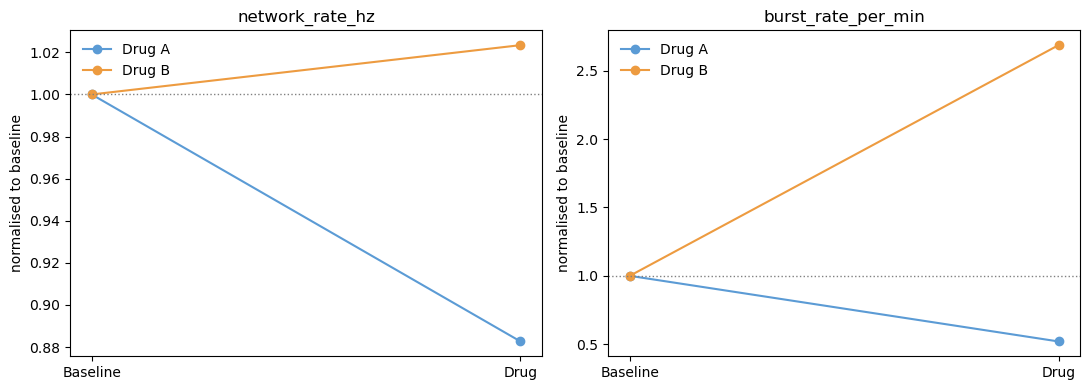

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, feature in zip(axes, ["network_rate_hz", "burst_rate_per_min"]):
    for drug, color in [("A", "#5b9bd5"), ("B", "#ed9b40")]:
        d = results[results["Drug"] == drug].set_index("Conditions")
        if {"Baseline", "Drug"} <= set(d.index):
            vals = np.array([d.loc["Baseline", feature], d.loc["Drug", feature]])
            ax.plot(["Baseline", "Drug"], vals / vals[0], "o-", color=color, label=f"Drug {drug}")
    ax.axhline(1, color="gray", ls=":", lw=1)
    ax.set_title(feature); ax.set_ylabel("normalised to baseline"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 3. Per-unit statistics

The comparison above has **one number per recording**, so there is nothing to
run a statistical test on. But each recording contains hundreds of curated
units, each with its own firing rate, CV of ISI and Fano factor (Part 3). We
can compare those **distributions** between Baseline and Drug.

### Worked example — collect the curated units of every recording

In [5]:
def unit_table(row):
    rec = mea.open_recording(row, data_root=DATA_ROOT)
    duration = rec.get_num_frames() / rec.get_sampling_frequency()
    sorting = mea.load_sorting(row, data_root=DATA_ROOT)
    feats = mea.unit_features(mea.sorting_to_spikes(sorting), duration, sorting=sorting)
    clean = mea.curate_units(feats)                      # same curation as Part 3
    return clean.assign(Drug=row["Drug"], Conditions=row["Conditions"], UID=row["UID"])

units = pd.concat([unit_table(r) for _, r in mine.iterrows()])
units.groupby(["Drug", "Conditions"]).size().rename("curated units")

Drug  Conditions
A     Baseline      225
      Drug          212
B     Baseline      193
      Drug          198
Name: curated units, dtype: int64

### ✎ Your turn — compare the typical unit, not the average

Firing rates are strongly **skewed** (remember the long tail in Part 3): a few
very active units pull the *mean* up. The **median** describes the typical
unit much better. Compute the % change of the median firing rate for Drug A.

In [6]:
a = units[units["Drug"] == "A"]
base_rates = a.loc[a["Conditions"] == "Baseline", "firing_rate_hz"]
drug_rates = a.loc[a["Conditions"] == "Drug", "firing_rate_hz"]

# TODO: use the MEDIAN of each group instead of the mean (.mean() -> .median()).
pct_change_median = 100 * (drug_rates.mean() - base_rates.mean()) / base_rates.mean()

mea.check(pct_change_median,
          100 * (drug_rates.median() - base_rates.median()) / base_rates.median(),
          hint="replace all three .mean() with .median()")
print(f"Drug A changed the median unit firing rate by {pct_change_median:.0f}%")

[X] not quite yet.
   hint: replace all three .mean() with .median()
   you got: -11.732818651081136
   expected ~ -27.79226733491382
Drug A changed the median unit firing rate by -12%


### Worked example — test every feature, for both drugs

`mea.compare_unit_features` runs a **Mann–Whitney U test** for each feature
and drug:

- **unpaired**, because the baseline units and the drug units are not the same
  neurons (we cannot match units across recordings),
- **rank-based**, so it does not assume normal distributions — it asks whether
  values in one group tend to be larger than in the other.

We run 3 features x 2 drugs = 6 tests. The more tests, the more likely one is
"significant" by chance, so `p_bonferroni` multiplies each p-value by the
number of tests (the **Bonferroni correction**).

In [7]:
stats = mea.compare_unit_features(units)
stats.round(4)

,Drug,feature,n_baseline,n_drug,median_baseline,median_drug,pct_change_median,p_value,p_bonferroni
0,A,firing_rate_hz,225,212,3.4899,2.5200,-27.7923,0.0001,0.0009
1,A,cv_isi,225,212,2.4511,2.1312,-13.0493,0.0157,0.0942
2,A,fano,225,212,5.8258,4.3040,-26.1212,0.0046,0.0277
3,B,firing_rate_hz,193,198,2.8824,2.9189,1.2668,0.8143,1.0000
4,B,cv_isi,193,198,2.0775,2.2213,6.9222,0.2858,1.0000
5,B,fano,193,198,2.7481,4.2680,55.3064,0.0051,0.0307


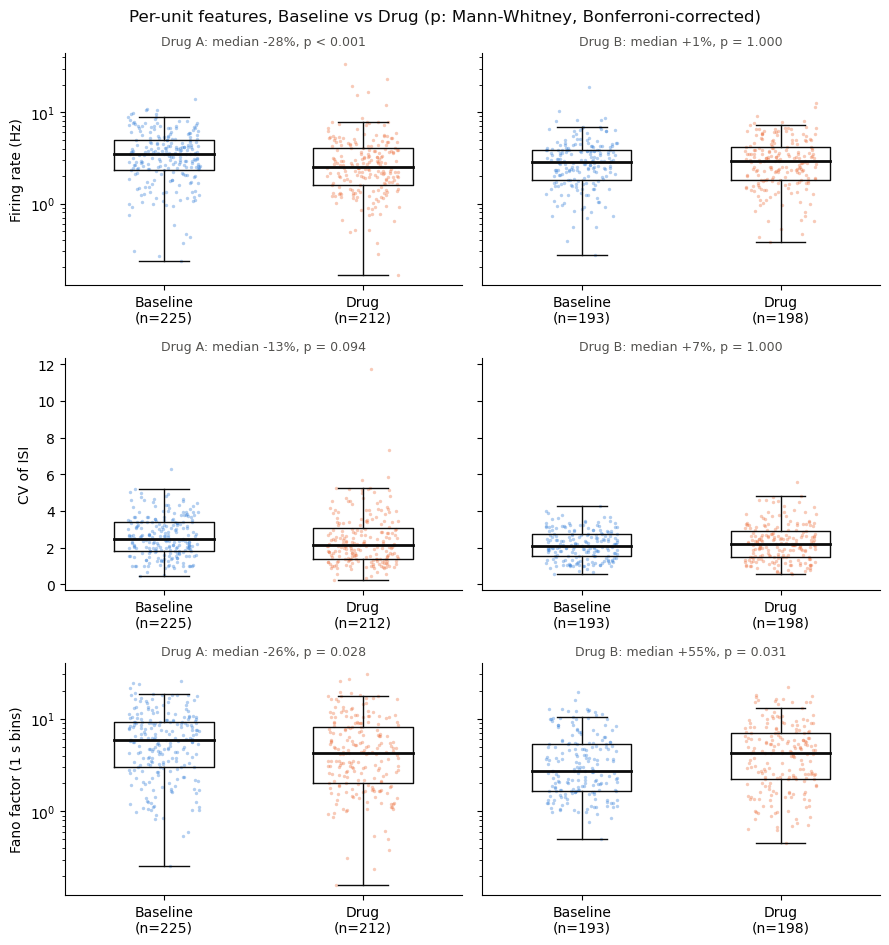

In [8]:
mea.plot_unit_comparison(units, stats)
plt.show()

> **💬 Discuss:**
> - Which features changed, in which direction, and for which drug? Is a
>   change that is *statistically* significant also *large* (look at the %
>   change of the median)?
> - With hundreds of units, even tiny differences become "significant". But
>   all units of one condition come from **one culture**: they are not
>   independent replicates of the drug experiment. What would you need to
>   claim that the *drug* (and not this particular culture) caused the change?

## 4. Reporting

- State the **goal**; revisit it in your conclusion.
- **Results:** descriptive statistics, no interpretation; back any difference
  with an appropriate statistical test (e.g. the per-unit tests above), and
  state what your *n* is (units? recordings? cultures?).
- **Discussion:** conclusions, the evidence for them, and the limitations (how
  sensitive were your burst counts to the threshold you chose?).
- **Figures:** clear labels, units, and self-contained captions.

> **✎ Your turn (writing):** Did Drug A and Drug B differ? Which feature showed the
> clearest effect? What would you improve with more time or more recordings?